# Explanation Evaluation
To evaluate the performance of my explanations, I need to compute the AUROC curve. I will do that for three cases:
- Token-Level Probabilities (baseline)
- Explanations Similarity
- Random Forest - Explanations Similarity + Linter Features

In [5]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.metrics import roc_curve, auc

In [6]:
ground_truth = pd.read_csv('datasets/evaluation_python_solutions_1.csv')
ground_truth['original_index'] = ground_truth.index
ground_truth = ground_truth.sort_values(by=['problem_title', 'original_index'])

In [7]:
ground_truth.shape

(1160, 15)

In [8]:
ground_truth.head()

,problem_title,code_line,is_readable,correct_naming,has_good_length,is_logic_straightforward,is_consistently_formatted,avoid_side_effects,dry,respect_language_practice,error_handling,extreme_error,sum_criteria,good,original_index
875,A+B Again?,t = int(input()),1,0,1,1,1,1,1,1,0,0,7,0,875
876,A+B Again?,for _ in range(t):,1,1,1,1,1,1,1,1,1,0,9,1,876
877,A+B Again?,n = int(input()),1,0,1,1,1,1,0,1,0,0,6,0,877
878,A+B Again?,tens_digit = n // 10,1,1,1,1,1,1,1,1,1,0,9,1,878
879,A+B Again?,units_digit = n % 10,1,1,1,1,1,1,1,1,1,0,9,1,879


In [9]:
ground_truth_classes = list(map(int, list(ground_truth['good'])))

In [10]:
def plot_multiple_roc_curves(roc_data):
    """
    roc_data: list of tuples (label, y_true, y_score)
    """
    fig = go.Figure()

    for label, y_true, y_score in roc_data:
        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)

        fig.add_trace(
            go.Scatter(
                x=fpr, y=tpr,
                mode='lines',
                name=f'{label} (AUROC = {roc_auc:.4f})'
            )
        )

    # Add diagonal
    fig.add_trace(
        go.Scatter(
            x=[0, 1], y=[0, 1],
            mode='lines',
            name='Random chance',
            line=dict(dash='dash', color='gray')
        )
    )

    fig.update_layout(
        title='ROC Curves',
        xaxis_title='False Positive Rate',
        yaxis_title='True Positive Rate',
        xaxis=dict(range=[0, 1]),
        yaxis=dict(range=[0, 1.05]),
        legend=dict(x=0.6, y=0.05),
        width=700,
        height=500
    )

    fig.show()

In [11]:
def get_auroc(ground_truth, predicted_probs):
    fpr, tpr, thresholds = roc_curve(ground_truth, predicted_probs)
    plot_roc_curve(fpr, tpr)

In [12]:
all_probabilities = pd.read_csv('datasets/all_probabilities.csv')

In [13]:
roc_data = [
    ('Baseline', ground_truth_classes, list(all_probabilities['token_prob'])),
    ('Similarity 2', ground_truth_classes, list(all_probabilities['similarity_2'])),
    ('Similarity 3', ground_truth_classes, list(all_probabilities['similarity_3'])),
    ('Similarity 4', ground_truth_classes, list(all_probabilities['similarity_4'])),
    ('Similarity 5', ground_truth_classes, list(all_probabilities['similarity_5'])),
    ('RF with Sim', ground_truth_classes, list(all_probabilities['rf_with_sim'])),
    ('RF without Sim', ground_truth_classes, list(all_probabilities['rf_without_sim']))
]

In [14]:
only_one = [('RF with Sim', ground_truth_classes, list(all_probabilities['rf_with_sim']))]

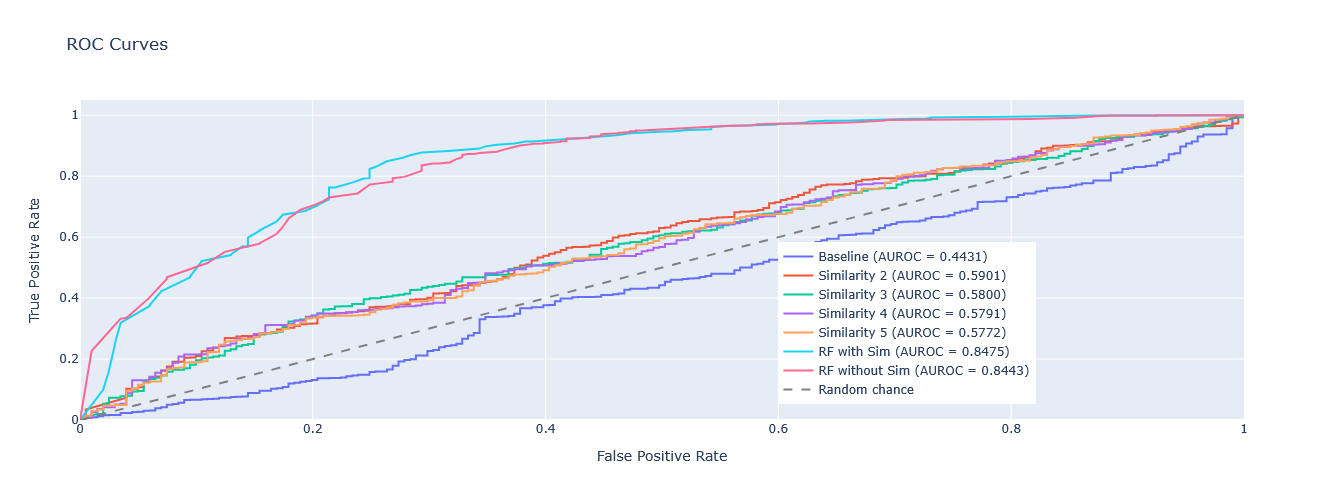

In [15]:
plot_multiple_roc_curves(roc_data)

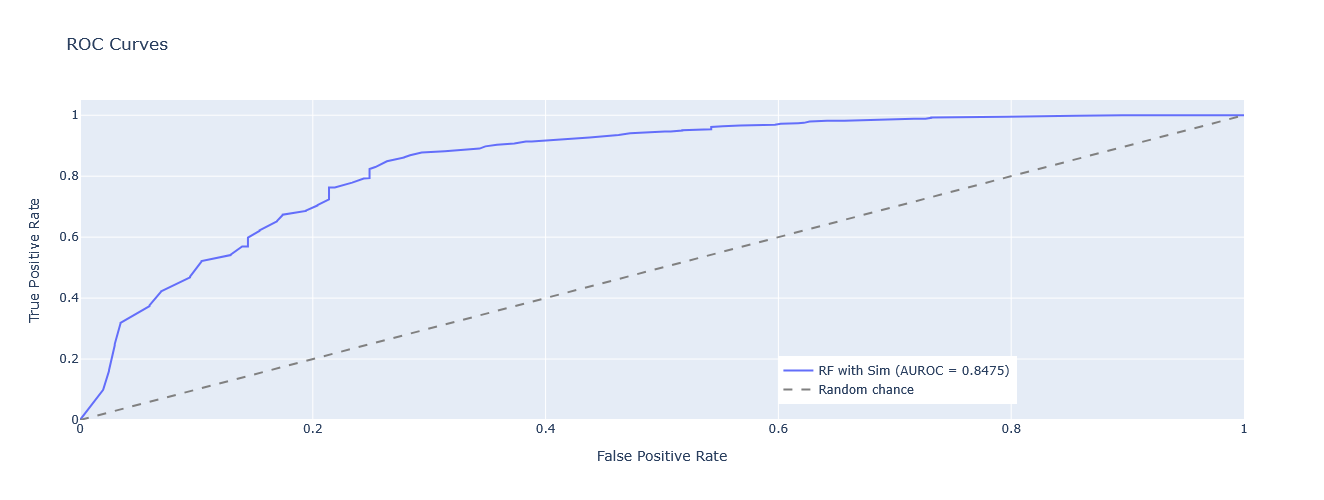

In [16]:
plot_multiple_roc_curves(only_one)

In [17]:
from sklearn.metrics import roc_curve

# y_true = your true labels
# y_score = your model's predicted probabilities

fpr, tpr, thresholds = roc_curve(ground_truth_classes, list(all_probabilities['rf_with_sim']))

# 1. Youden's J statistic
j_scores = tpr - fpr
best_index = j_scores.argmax()
best_threshold = thresholds[best_index]

print(f"Best threshold by Youden's J: {best_threshold:.3f}")


Best threshold by Youden's J: 0.768


In [18]:
!pip install MLstatkit

Defaulting to user installation because normal site-packages is not writeable


In [19]:
from MLstatkit.stats import Delong_test
from sklearn.metrics import roc_auc_score

y_true = ground_truth_classes
rf_with_sim = all_probabilities['rf_with_sim']
rf_without_sim = all_probabilities['rf_without_sim']

# Compute AUROCs
auc_with_sim = roc_auc_score(y_true, rf_with_sim)
auc_without_sim = roc_auc_score(y_true, rf_without_sim)

# Perform DeLong test
stat, p_value = Delong_test(y_true, rf_with_sim, rf_without_sim)

print(f"AUROC RF with Sim: {auc_with_sim:.4f}")
print(f"AUROC RF without Sim: {auc_without_sim:.4f}")
print(f"DeLong's test statistic: {stat:.4f}")
print(f"p-value: {p_value:.5f}")

AUROC RF with Sim: 0.8475
AUROC RF without Sim: 0.8443
DeLong's test statistic: -0.2824
p-value: 0.77764
